# Pipeline de análise de imagens de RX normal, pneumonia ou COVID19 visando emissão de laudos / diagnóstico automatizados a serem confirmados pelo profissional de medicina

### Rede Neural VGG16

In [6]:
import glob
import shutil
import cv2
import os
from PIL import Image
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import *
from tensorflow.keras.preprocessing import *
from keras.applications.vgg16 import VGG16
from keras import layers
# from skimage.feature import local_binary_pattern

import warnings
# Ignorar warnings
warnings.filterwarnings('ignore')

In [7]:
name_list = glob.glob('dataset/NORMAL/*')

labels = ['NORMAL', 'COVID', 'PNEUMONIA']

# Carregando as imagens de treinamento e seus rótulos
X= []
y = []

for name in name_list:
  y.append(0)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

10192

In [8]:
name_list = glob.glob('dataset/COVID/*')

for name in name_list:
  y.append(1)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

13808

In [9]:
name_list = glob.glob('dataset/PNEUMONIA/*')
for name in name_list:
  y.append(2)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

15153

In [10]:
# 1. Pré-aloca a matriz global X e o array de rótulos y com o tamanho total exato (15153)
total_imagens = 15153
X = np.zeros((total_imagens, 100, 100, 3), dtype=np.uint8)
y = np.zeros((total_imagens, 1), dtype=np.int32)

idx = 0  # Índice de controlo global

# --- 2. NORMAL (Rótulo 0) ---
name_list = glob.glob('dataset/NORMAL/*')
for name in name_list:
    img = cv2.imread(name)
    if img is not None:
        img = cv2.resize(img, (100, 100))
        X[idx] = img
        y[idx] = 0
        idx += 1

# --- 3. COVID (Rótulo 1) ---
name_list = glob.glob('dataset/COVID/*')
for name in name_list:
    img = cv2.imread(name)
    if img is not None:
        img = cv2.resize(img, (100, 100))
        X[idx] = img
        y[idx] = 1
        idx += 1

# --- 4. PNEUMONIA (Rótulo 2) ---
name_list = glob.glob('dataset/PNEUMONIA/*')
for name in name_list:
    img = cv2.imread(name)
    if img is not None:
        img = cv2.resize(img, (100, 100))
        X[idx] = img
        y[idx] = 2
        idx += 1

# 5. Normalização final otimizada (sem picos de memória)
X = X.astype(np.float32)
X /= 255.0

print("Carregamento concluído com sucesso!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Carregamento concluído com sucesso!
X shape: (15153, 100, 100, 3)
y shape: (15153, 1)


In [11]:
print(len(X))
print(X.shape)
print(y.shape)

15153
(15153, 100, 100, 3)
(15153, 1)


In [12]:
import numpy as np
import random

# 1. Embaralha as listas Python originais
combined = list(zip(X, y))
random.seed(42)
random.shuffle(combined)
X_shuffled, y_shuffled = zip(*combined)

# 2. Define os pontos de corte nas listas (80% treino, 10% val, 10% teste)
train_end = int(0.8 * len(X_shuffled))
val_end = int(0.9 * len(X_shuffled))

# 3. Converte e normaliza cada pedaço diretamente (evita o pico de memória)
X_train = np.array(X_shuffled[:train_end], dtype=np.float32) / 255.0
y_train = np.array(y_shuffled[:train_end]).reshape(-1, 1)

X_val = np.array(X_shuffled[train_end:val_end], dtype=np.float32) / 255.0
y_val = np.array(y_shuffled[train_end:val_end]).reshape(-1, 1)

X_test = np.array(X_shuffled[val_end:], dtype=np.float32) / 255.0
y_test = np.array(y_shuffled[val_end:]).reshape(-1, 1)

# 4. Imprime os tamanhos para confirmar
print("Treino:", X_train.shape, y_train.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_test.shape, y_test.shape)

Treino: (12122, 100, 100, 3) (12122, 1)
Validação: (1515, 100, 100, 3) (1515, 1)
Teste: (1516, 100, 100, 3) (1516, 1)


In [13]:
# Normaliza diretamente nos arrays existentes sem alocar nova memória
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0

In [14]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(100,100, 3))

# Congela os pisos do modelo VGG16
for layer in base_model.layers:
    layer.trainable = False

model = Sequential()
model.add(base_model)
model.add(Flatten())
model.add(Dense(1024))
model.add(Activation("relu"))
model.add(Dense(512))
model.add(Activation("relu"))
model.add(Dense(1))
model.add(Activation("sigmoid"))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,959,617 (76.14 MB)

 Trainable params: 5,244,929 (20.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:
%%time
learning_rate = 0.0001 # Taxa de aprendizado inicial
decay_steps = 10       # Número de épocas para aplicar o decaimento
decay_rate = 1         # Taxa de redução da taxa de aprendizado

# Inicializa o escalonador de taxa de aprendizado
lr_scheduler = tf.keras.optimizers.schedules.ExponentialDecay(learning_rate, decay_steps, decay_rate)
optimizer1 = tf.keras.optimizers.Adam(learning_rate = lr_scheduler)
model.compile(optimizer = optimizer1, loss = tf.keras.losses.CategoricalCrossentropy(),metrics =['accuracy'])

history = model.fit(X_train, y_train, batch_size = 32, epochs = 5, validation_data = (X_val, y_val))

Epoch 1/5
379/379 ━━━━━━━━━━━━━━━━━━━━ 266s 695ms/step - accuracy: 0.6729 - loss: 0.0000e+00 - val_accuracy: 0.6680 - val_loss: 0.0000e+00
Epoch 2/5
379/379 ━━━━━━━━━━━━━━━━━━━━ 254s 669ms/step - accuracy: 0.6729 - loss: 0.0000e+00 - val_accuracy: 0.6680 - val_loss: 0.0000e+00
Epoch 3/5
379/379 ━━━━━━━━━━━━━━━━━━━━ 255s 674ms/step - accuracy: 0.6729 - loss: 0.0000e+00 - val_accuracy: 0.6680 - val_loss: 0.0000e+00
Epoch 4/5
379/379 ━━━━━━━━━━━━━━━━━━━━ 252s 665ms/step - accuracy: 0.6729 - loss: 0.0000e+00 - val_accuracy: 0.6680 - val_loss: 0.0000e+00
Epoch 5/5
379/379 ━━━━━━━━━━━━━━━━━━━━ 251s 662ms/step - accuracy: 0.6729 - loss: 0.0000e+00 - val_accuracy: 0.6680 - val_loss: 0.0000e+00
CPU times: total: 2h 18min 58s
Wall time: 21min 21s


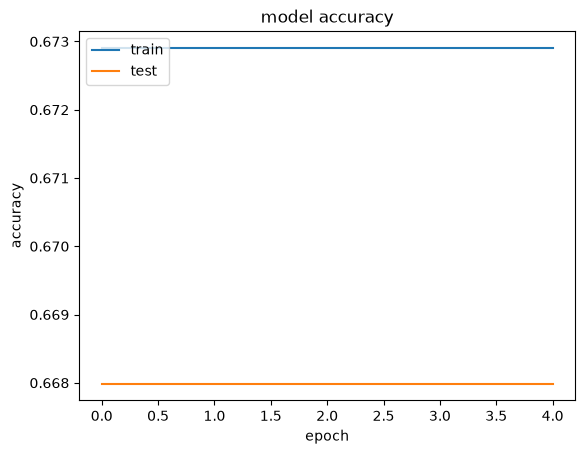

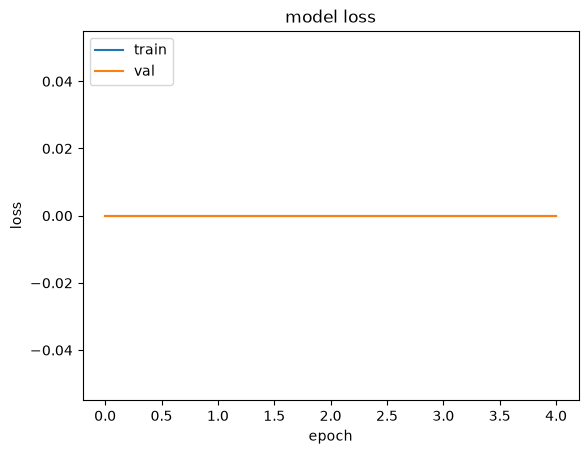

In [16]:
from matplotlib import pyplot  as plt

# Resumo das acurácias
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'],loc ='upper left')
plt.show()

# Resumo das perdas
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','val'],loc ='upper left')
plt.show()

In [17]:
model.save('model1.h5')

In [18]:
model1 = load_model('model1.h5')

In [19]:

y_hat = model1.predict(X_test)
def predict(y_hat):
    y_hat[y_hat >= 0.5] =1
    y_hat[y_hat<0.5] =0
    return y_hat
y_pred = predict(y_hat)
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 29s 601ms/step
0.674802110817942


In [20]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
labels = ['Covid', 'Normal', 'Pneumonia']
report = classification_report(y_test, y_pred, target_names=labels)
print(report)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy}")

              precision    recall  f1-score   support

       Covid       0.67      1.00      0.81      1023
      Normal       0.00      0.00      0.00       368
   Pneumonia       0.00      0.00      0.00       125

    accuracy                           0.67      1516
   macro avg       0.22      0.33      0.27      1516
weighted avg       0.46      0.67      0.54      1516

Accuracy: 0.674802110817942


[[1023    0    0]
 [ 368    0    0]
 [ 125    0    0]]


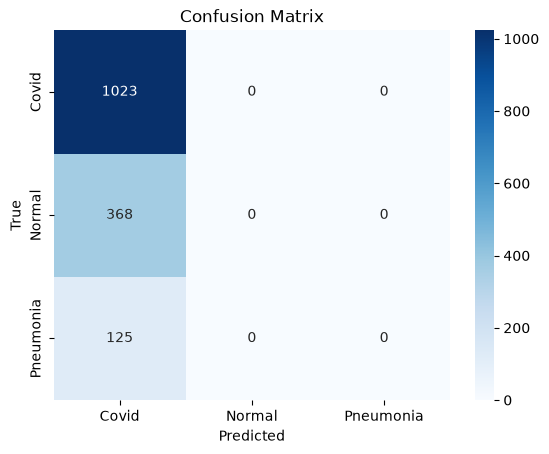

In [21]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

# Configuração do eixo x e eixo y
tick_labels = ['Covid', 'Normal', 'Pneumonia']
plt.xticks(np.arange(len(tick_labels)) + 0.5, tick_labels)
plt.yticks(np.arange(len(tick_labels)) + 0.5, tick_labels)

# Nomeia os eixos
plt.xlabel('Predicted')
plt.ylabel('True')

# Mostra o gráfico
plt.title('Confusion Matrix')
plt.show()